In [23]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import torch
from transformers import AutoProcessor, AutoModelForCausalLM, Gemma3ForConditionalGeneration

In [15]:
INPUT_DIR = Path("/kaggle/input/competitions/name-that-llm")
TEST_DIR = INPUT_DIR / "test.csv"
TRAIN_DIR = INPUT_DIR / "train.csv"
LLM_PATH = Path("/kaggle/input/models/google/gemma-3/transformers/gemma-3-12b-it/1")

## Imports and Visualizations

In [16]:
test_df = pd.read_csv(TEST_DIR)
train_df = pd.read_csv(TRAIN_DIR)

In [17]:
train_df.head()

,id,prompt_id,text,model
0,0018b3765972,p081,"When a language dies, a particular astronomy d...",qwen3.8-max
1,0041ac86ee93,p073,Data science communities matter because they a...,claude-sonnet-5
2,005a19083eae,p120,"In the final twilight of time, the last embers...",gemini-3.6-flash
3,009319596f10,p073,Data science communities matter because they t...,gpt-5.6-terra
4,00d3e8c92596,p097,"Deep inside each ear, three tiny loops of bone...",glm-5.3-flash


In [18]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2699 entries, 0 to 2698
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   id         2699 non-null   object
 1   prompt_id  2699 non-null   object
 2   text       2699 non-null   object
 3   model      2699 non-null   object
dtypes: object(4)
memory usage: 84.5+ KB


<BarContainer object of 18 artists>

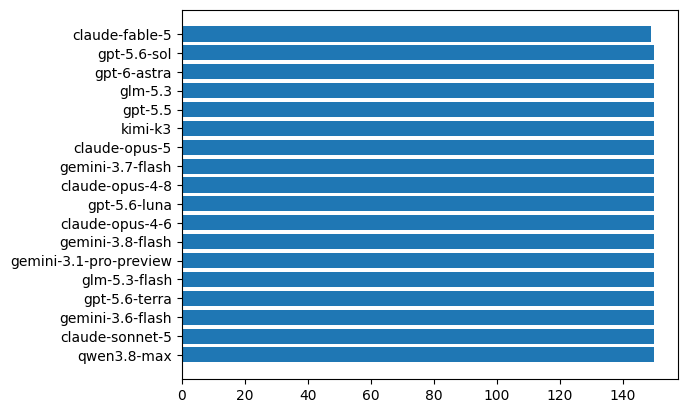

In [19]:
models_counts = train_df["model"].value_counts()
plt.barh(models_counts.index, models_counts.values)

In [20]:
print(f"claude fable 5: {models_counts["claude-fable-5"]}, others: {models_counts["gpt-5.5"]}")

claude fable 5: 149, others: 150


In [26]:
processor = AutoProcessor.from_pretrained(LLM_PATH)
model = Gemma3ForConditionalGeneration.from_pretrained(
    LLM_PATH,
    device_map = "auto",
    torch_dtype = torch.bfloat16,
).eval()

Loading weights:   0%|          | 0/1065 [00:00<?, ?it/s]

Some parameters are on the meta device because they were offloaded to the cpu.


In [27]:
LABELS = ["gpt-5.5","gpt-5.6-luna","gpt-5.6-sol","gpt-5.6-terra","gpt-6-astra",
          "gemini-3.1-pro-preview","gemini-3.6-flash","gemini-3.7-flash","gemini-3.8-flash",
          "claude-fable-5","claude-opus-4-6","claude-opus-4-8","claude-opus-5","claude-sonnet-5",
          "qwen3.8-max","glm-5.3","glm-5.3-flash","kimi-k3"]
LETTERS = [chr(65 + i) for i in range(len(LABELS))]
SYSTEM = ("You are an expert in forensic linguistics. You identify which AI model "
          "wrote a passage from its vocabulary, tone, punctuation and structure.")

In [28]:
def build_message(text):
    options = "\n".join(f"{l}. {m}" for l, m in zip(LETTERS, LABELS))
    user = (f'Passage:\n"""\n{text}\n"""\n\n'
            f"Which model wrote this passage?\n{options}\n\nAnswer with a single letter.")

    return [
        {"role" : "system", "content" : [{"type": "text", "text": SYSTEM}]},
        {"role" : "user", "content" : [{"type" : "text", "text" : user}]}
    ]

letter_ids = [processor.tokenizer.encode(l, add_special_tokens=False)[0] for l in LETTERS]

@torch.no_grad()
def score(text):
    prompt = processor.apply_chat_template(build_message(text), tokenize=False,
                                           add_generation_prompt=True)
    inputs = processor(text = prompt, return_tensors = "pt").to(model.device)
    logits = model(**inputs).logits[0, -1]

    return torch.log_softmax(logits[letter_ids].float(), dim=-1).cpu()

In [29]:
test_score = torch.stack([score(t) for t in test_df["text"]])
test_score = test_score - test_score.mean(0, keepdim=True)
pred = [LABELS[i] for i in test_score.argmax(1).tolist()]
pd.DataFrame({"id": test_df["id"], "model": pred}).to_parquet("submission.parquet", index=False)